# ETH / CRCLB 短线信号回测与参数优化

目标：验证当前信号在真实后续价格上的表现，并在严格的时间切分下寻找更稳健的参数。

- 数据：Binance 公共 5m、15m、1h 已收盘 K 线，自 2026-06-11 起。
- 交易定义：信号于 15m 收盘确认，固定持有 2 小时；持仓期间忽略重复信号。
- 成本：每笔完整交易扣除 0.20%（手续费与滑点的合并假设）。
- 防过拟合：前 70% 仅用于选参数，后 30% 作为完全未参与调参的样本外验证。
- “卖出成功”：按可做空口径，2 小时后的空头净收益大于 0；若只用于减仓，也等价于价格跌幅超过成本。

注意：短历史、单一市场阶段的结果不能保证未来收益。参数排序以 Wilson 置信下界为主，并要求训练集至少 20 笔非重叠交易。

数据起点：2026-06-11T00:00:00Z；2小时固定持有；每笔双边成本假设：0.2%
ETHUSDT: 9,134 根15分钟评估点，2026-06-11 03:44:59.999000+00:00 至 2026-09-14 06:59:59.999000+00:00
CRCLBUSDT: 9,062 根15分钟评估点，2026-06-11 21:44:59.999000+00:00 至 2026-09-14 06:59:59.999000+00:00

未参与调参的后30%验证集：
   symbol 方向 variant  trades   命中率   平均净收益  profit_factor   累计净收益    最大回撤
  ETHUSDT 买入    现有规则     206 29.6% -0.118%       0.677005 -22.45% -33.13%
  ETHUSDT 买入    优化规则     230 33.0%  -0.16%       0.574243 -31.46% -41.28%
  ETHUSDT 卖出    现有规则      64 23.4% -0.361%       0.184747 -20.73% -20.73%
  ETHUSDT 卖出    优化规则      53 22.6% -0.377%       0.166037 -18.22% -18.22%
CRCLBUSDT 买入    现有规则     186 39.8% -0.142%       0.734061 -24.57% -25.78%
CRCLBUSDT 买入    优化规则     262 37.4% -0.097%       0.803725  -24.6% -35.18%
CRCLBUSDT 卖出    现有规则      97 34.0% -0.271%       0.431056 -23.54% -23.54%
CRCLBUSDT 卖出    优化规则      55 32.7%  -0.22%       0.513513 -11.66% -14.54%

训练集选出的参数：
{
  "ETHUSDT_buy": {
    "threshold": 55,
    "rsi_low": 50,
    "rsi_hig

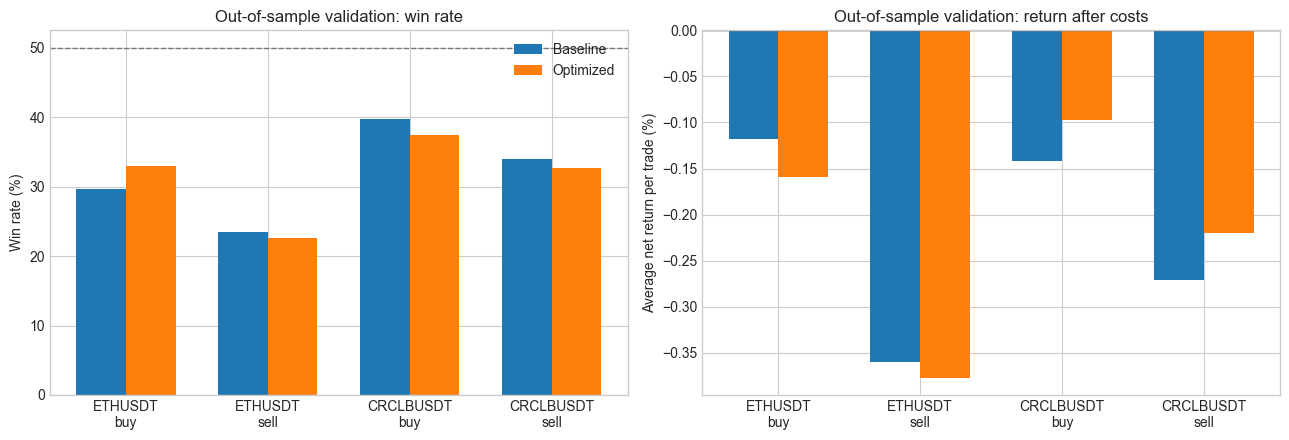

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd().resolve()
if project_root.name == 'analysis':
    project_root = project_root.parent
sys.path.insert(0, str(project_root / 'analysis'))

from backtest_core import run_analysis
results, selected_parameters = run_analysis(refresh=False)

## 阅读结果的方法

优先看“验证集”的交易数、命中率与平均净收益。若优化规则只提高命中率、但平均净收益仍小于零，说明它没有克服交易成本；若交易数很少，则结论不稳，应继续积累数据。Profit Factor 大于 1 才表示总盈利超过总亏损。